In [21]:
import pandas as pd
import numpy as np
import json
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

pd.set_option("display.max_columns", 200)
pd.set_option("display.max_rows", 200)

# adjust the path if needed; right now you said this file already has the new schema
df = pd.read_parquet("../ai_logs.parquet")

In [22]:
df.head()

,id,session_id,player_mark,board,legal_moves,ai_move,game_status,timestamp,mcts_iterations,exploration_constant,visit_counts_json,action_scores_json,policy_vector_json,best_visit_count,best_q_value,move_confidence,branching_factor,explored_actions,mcts_tree_size,rollout_count,rollout_depth_avg,rollout_depth_max,mcts_search_duration_ms,ai_latency_ms,ai_difficulty,final_result
0,1231e27f-78cb-4eb1-bd1e-52e58451bb00,ed3f70c1-49f5-4ac1-a235-b9c8fdaedacb,X,"[["""", """", """"], ["""", """", """"], ["""", """", """"]]","[{""row"": 0, ""col"": 0}, {""row"": 0, ""col"": 1}, {...","{""row"": 1, ""col"": 0}",IN_PROGRESS,2025-12-07 18:25:17.417802,300,0.7071067811865475,"{'0,0': 33, '0,1': 22, '0,2': 21, '1,0': 49, '...","{'0,0': -0.8484848484848485, '0,1': -0.9545454...","{'0,0': 0.11, '0,1': 0.07333333333333333, '0,2...",49,-0.7755102040816326,0.16333333333333333,9,9,301,300,5.07,8,37,37,EASY,None
1,929faa30-06a1-4a2d-9581-070d58104a37,ed3f70c1-49f5-4ac1-a235-b9c8fdaedacb,O,"[["""", """", """"], [""X"", """", """"], ["""", """", """"]]","[{""row"": 0, ""col"": 0}, {""row"": 0, ""col"": 1}, {...","{""row"": 1, ""col"": 2}",IN_PROGRESS,2025-12-07 18:25:17.481851,300,0.7071067811865475,"{'0,0': 22, '0,1': 25, '0,2': 18, '1,1': 50, '...","{'0,0': -0.9545454545454546, '0,1': -0.92, '0,...","{'0,0': 0.07333333333333333, '0,1': 0.08333333...",97,-0.6804123711340206,0.3233333333333333,8,8,301,300,3.973333333333333,7,32,32,EASY,None
2,60eb3802-c538-4a02-8b14-c7240368163f,ed3f70c1-49f5-4ac1-a235-b9c8fdaedacb,X,"[["""", """", """"], [""X"", """", ""O""], ["""", """", """"]]","[{""row"": 0, ""col"": 0}, {""row"": 0, ""col"": 1}, {...","{""row"": 0, ""col"": 2}",IN_PROGRESS,2025-12-07 18:25:17.532817,300,0.7071067811865475,"{'0,0': 15, '0,1': 26, '0,2': 130, '1,1': 31, ...","{'0,0': -0.9333333333333333, '0,1': -0.7692307...","{'0,0': 0.05, '0,1': 0.08666666666666667, '0,2...",130,-0.5153846153846153,0.43333333333333335,7,7,301,300,3.0566666666666666,6,31,31,EASY,None
3,899783cd-b4fa-4223-a9d0-a625f37fb373,ed3f70c1-49f5-4ac1-a235-b9c8fdaedacb,O,"[["""", """", ""X""], [""X"", """", ""O""], ["""", """", """"]]","[{""row"": 0, ""col"": 0}, {""row"": 0, ""col"": 1}, {...","{""row"": 0, ""col"": 1}",IN_PROGRESS,2025-12-07 18:25:17.595009,300,0.7071067811865475,"{'0,0': 19, '0,1': 199, '1,1': 25, '2,0': 29, ...","{'0,0': -0.6842105263157895, '0,1': -0.2160804...","{'0,0': 0.06333333333333334, '0,1': 0.66333333...",199,-0.21608040201005024,0.6633333333333333,6,6,191,300,1.4466666666666668,5,43,43,EASY,None
4,1552d3f4-84b9-4a7e-b659-5d00b3ff705c,ed3f70c1-49f5-4ac1-a235-b9c8fdaedacb,X,"[["""", ""O"", ""X""], [""X"", """", ""O""], ["""", """", """"]]","[{""row"": 0, ""col"": 0}, {""row"": 1, ""col"": 1}, {...","{""row"": 2, ""col"": 1}",IN_PROGRESS,2025-12-07 18:25:17.629120,300,0.7071067811865475,"{'0,0': 16, '1,1': 26, '2,0': 6, '2,1': 242, '...","{'0,0': -0.5625, '1,1': -0.4230769230769231, '...","{'0,0': 0.05333333333333334, '1,1': 0.08666666...",242,-0.09090909090909091,0.8066666666666666,5,5,107,300,0.53,4,14,14,EASY,None


In [23]:
df.shape

(1800, 26)

In [24]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1800 entries, 0 to 1799
Data columns (total 26 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   id                       1800 non-null   object        
 1   session_id               1800 non-null   object        
 2   player_mark              1800 non-null   object        
 3   board                    1800 non-null   object        
 4   legal_moves              1800 non-null   object        
 5   ai_move                  1800 non-null   object        
 6   game_status              1800 non-null   object        
 7   timestamp                1800 non-null   datetime64[ns]
 8   mcts_iterations          1800 non-null   int64         
 9   exploration_constant     1800 non-null   object        
 10  visit_counts_json        1800 non-null   object        
 11  action_scores_json       1800 non-null   object        
 12  policy_vector_json       1800 non-

In [25]:
# How many game sessions?
df["session_id"].nunique()

200

In [26]:
# Moves per game (number of rows per session)
moves_per_game = df.groupby("session_id")["id"].count()
moves_per_game.describe()


count    200.0
mean       9.0
std        0.0
min        9.0
25%        9.0
50%        9.0
75%        9.0
max        9.0
Name: id, dtype: float64

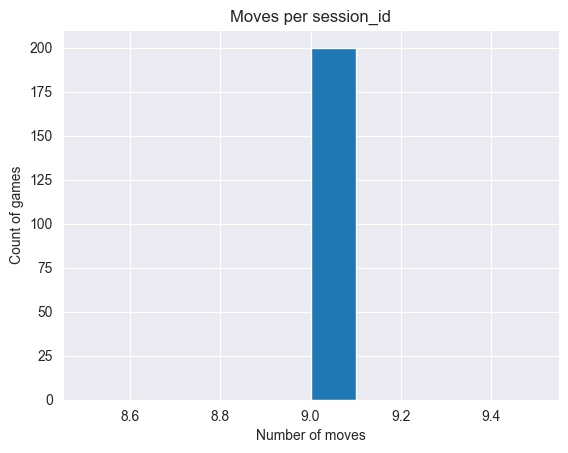

In [27]:
moves_per_game.hist(bins=10)
plt.title("Moves per session_id")
plt.xlabel("Number of moves")
plt.ylabel("Count of games")
plt.show()


In [29]:
def parse_board(board_str):
    """
    Parse the board column, which is now a 3x3 JSON array of strings:
    [
      ["", "O", "X"],
      ["X", "", "O"],
      ["", "", ""]
    ]

    Returns a flat list of 9 values in row-major order.
    """
    mat = json.loads(board_str)  # 3x3 list of strings
    flat = []
    for row in mat:
        for cell in row:
            if cell == "" or cell is None:
                flat.append("EMPTY")
            else:
                flat.append(cell)
    return flat


# Look at first few boards
example_boards = df["board"].head(5).apply(parse_board)
example_boards.tolist()


[['EMPTY',
  'EMPTY',
  'EMPTY',
  'EMPTY',
  'EMPTY',
  'EMPTY',
  'EMPTY',
  'EMPTY',
  'EMPTY'],
 ['EMPTY', 'EMPTY', 'EMPTY', 'X', 'EMPTY', 'EMPTY', 'EMPTY', 'EMPTY', 'EMPTY'],
 ['EMPTY', 'EMPTY', 'EMPTY', 'X', 'EMPTY', 'O', 'EMPTY', 'EMPTY', 'EMPTY'],
 ['EMPTY', 'EMPTY', 'X', 'X', 'EMPTY', 'O', 'EMPTY', 'EMPTY', 'EMPTY'],
 ['EMPTY', 'O', 'X', 'X', 'EMPTY', 'O', 'EMPTY', 'EMPTY', 'EMPTY']]

In [30]:
counter = Counter()

sample = df["board"].sample(min(1000, len(df)), random_state=0)
for values in sample.apply(parse_board):
    counter.update(values)

counter


Counter({'EMPTY': 5056, 'X': 2190, 'O': 1754})

In [31]:
def parse_ai_move(ai_move_str):
    """
    Parse the ai_move JSON object which should contain row and col fields.
    """
    obj = json.loads(ai_move_str)
    return obj["row"], obj["col"]

df["move_row"], df["move_col"] = zip(*df["ai_move"].map(parse_ai_move))
df[["move_row", "move_col"]].head()


,move_row,move_col
0,1,0
1,1,2
2,0,2
3,0,1
4,2,1


In [32]:
# How often does the AI choose each cell?
move_counts = df.groupby(["move_row", "move_col"])["id"].count().unstack(fill_value=0)
move_counts


move_col,0,1,2
move_row,,,
0,200,200,200
1,200,200,200
2,200,200,200


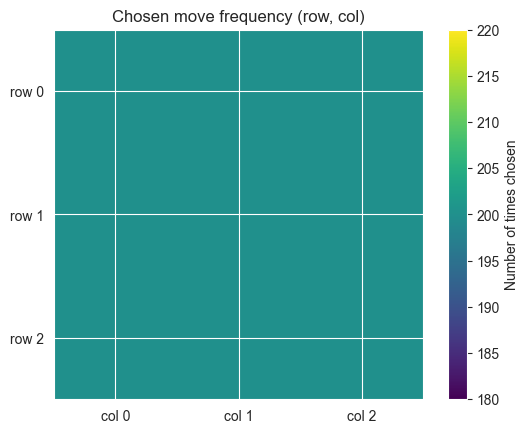

In [33]:
plt.imshow(move_counts.values, cmap="viridis")
plt.colorbar(label="Number of times chosen")
plt.xticks([0, 1, 2], ["col 0", "col 1", "col 2"])
plt.yticks([0, 1, 2], ["row 0", "row 1", "row 2"])
plt.title("Chosen move frequency (row, col)")
plt.show()



In [34]:
def parse_legal_moves(legal_moves_str):
    """
    legal_moves expected to be a JSON array like:
    [{"row":0,"col":1,...}, ...]
    """
    return json.loads(legal_moves_str)

def is_ai_move_legal(row):
    legal = parse_legal_moves(row["legal_moves"])
    return any(m["row"] == row["move_row"] and m["col"] == row["move_col"] for m in legal)

df["ai_move_legal"] = df.apply(is_ai_move_legal, axis=1)
df["ai_move_legal"].value_counts()

ai_move_legal
True    1800
Name: count, dtype: int64

In [35]:
df.groupby("session_id")["id"].count().sort_values(ascending=False).head(20)


session_id
00cecf09-1625-4c2a-8673-59e8ae6b95ea    9
02849387-baaa-47df-8dbd-e0465aa971ca    9
02db1f8e-5bf1-4800-ae71-f660fb13e747    9
04b44782-e959-4fc8-87f9-2e0d9abdbf00    9
06974e96-0811-4e47-8a60-d7a5a52ad78e    9
0a642cd5-1232-40e6-a611-ff0657a39e13    9
0c8815cb-e32b-42c8-8087-28198deda52a    9
11a036f9-e271-4e8b-9ed2-17698d96d8e6    9
1201b1ec-1bf8-47f0-81a1-b946fdc407ae    9
1317e9fc-0f6a-4340-8c69-dcf133893109    9
137d99ce-e056-488d-aa5a-2377b1186880    9
13c43b60-0000-4be8-b1a8-6f359f73b6cb    9
1526aac9-0be4-4a5c-895d-98adec5bffd7    9
15878d63-888e-4130-a2b2-330a20a0b667    9
158922a2-cad0-49a2-98a8-f3811293fad3    9
158b2c4c-e2ee-4360-bddc-20cc1219bbb4    9
16e4f340-4cbd-4468-a5f7-0280194b978b    9
17108c1e-8bdb-4725-ad4b-13b3d38873b1    9
17187b62-eebc-42fb-a49e-e906af30c137    9
1781f638-b361-4f25-a1d0-72cdfe85d378    9
Name: id, dtype: int64

In [37]:
df.groupby("session_id")["id"].count().value_counts()

id
9    200
Name: count, dtype: int64

In [38]:
sid = df["session_id"].iloc[0]
df[df["session_id"] == sid][["board", "ai_move", "player_mark", "game_status", "timestamp"]]

,board,ai_move,player_mark,game_status,timestamp
0,"[["""", """", """"], ["""", """", """"], ["""", """", """"]]","{""row"": 1, ""col"": 0}",X,IN_PROGRESS,2025-12-07 18:25:17.417802
1,"[["""", """", """"], [""X"", """", """"], ["""", """", """"]]","{""row"": 1, ""col"": 2}",O,IN_PROGRESS,2025-12-07 18:25:17.481851
2,"[["""", """", """"], [""X"", """", ""O""], ["""", """", """"]]","{""row"": 0, ""col"": 2}",X,IN_PROGRESS,2025-12-07 18:25:17.532817
3,"[["""", """", ""X""], [""X"", """", ""O""], ["""", """", """"]]","{""row"": 0, ""col"": 1}",O,IN_PROGRESS,2025-12-07 18:25:17.595009
4,"[["""", ""O"", ""X""], [""X"", """", ""O""], ["""", """", """"]]","{""row"": 2, ""col"": 1}",X,IN_PROGRESS,2025-12-07 18:25:17.629120
5,"[["""", ""O"", ""X""], [""X"", """", ""O""], ["""", ""X"", """"]]","{""row"": 2, ""col"": 0}",O,IN_PROGRESS,2025-12-07 18:25:17.659696
6,"[["""", ""O"", ""X""], [""X"", """", ""O""], [""O"", ""X"", """"]]","{""row"": 2, ""col"": 2}",X,IN_PROGRESS,2025-12-07 18:25:17.689376
7,"[["""", ""O"", ""X""], [""X"", """", ""O""], [""O"", ""X"", ""X""]]","{""row"": 0, ""col"": 0}",O,IN_PROGRESS,2025-12-07 18:25:17.717270
8,"[[""O"", ""O"", ""X""], [""X"", """", ""O""], [""O"", ""X"", ""...","{""row"": 1, ""col"": 1}",X,FINISHED,2025-12-07 18:25:17.753324
